# CP2 e CP3 — Análise de Incidentes em um SOC
**Atividade acadêmica de Ciência de Dados aplicada à Cibersegurança**

## Introdução
Analisamos os 50 eventos do arquivo `dataset_defesa_cibernetica_50.csv` para comparar eventos benignos e incidentes e avaliar um classificador inicial. A classe 0 representa eventos benignos; a classe 1 representa incidentes.

## Contexto do projeto
Este projeto foi desenvolvido em um ambiente de testes, como atividade acadêmica e exercício de análise de eventos de um SOC. Os resultados se limitam ao CSV utilizado e não representam validação para uso em produção.

**Não utilize informações confidenciais neste projeto.** Ao reproduzir a análise, não envie credenciais, dados pessoais, logs internos ou registros de clientes ao notebook, ao Google Colab ou a este repositório.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': False})

## Carregamento do CSV
Coloque o CSV na pasta do notebook. Se ele não estiver disponível, o Google Colab solicitará o upload. Os valores originais serão preservados.

In [2]:
arquivo = Path('dataset_defesa_cibernetica_50.csv')
if not arquivo.is_file():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Coloque dataset_defesa_cibernetica_50.csv na pasta do notebook e execute novamente.')
    enviados = files.upload()
    if arquivo.name not in enviados:
        raise FileNotFoundError('Envie o arquivo dataset_defesa_cibernetica_50.csv.')

dados = pd.read_csv(arquivo)
print(f'CSV carregado: {len(dados)} eventos.')

CSV carregado: 50 eventos.


## Visualização e verificação dos dados

In [3]:
colunas = ['falhas_login', 'ips_origem', 'trafego_saida_mb', 'hora_evento', 'incidente']
assert dados.columns.tolist() == colunas, 'Colunas diferentes das esperadas.'
assert len(dados) == 50, 'São esperados 50 eventos.'
assert not dados.isna().any().any(), 'Há valores ausentes.'
assert all(pd.api.types.is_numeric_dtype(dados[c]) for c in colunas), 'Há valores não numéricos.'
assert set(dados['incidente'].unique()) == {0, 1}, 'Classes inválidas.'
assert dados['hora_evento'].between(0, 23).all(), 'Hora fora do intervalo.'
assert (dados[colunas[:3]] >= 0).all().all(), 'Há valores negativos.'
for coluna in ['falhas_login', 'ips_origem', 'hora_evento', 'incidente']:
    assert (dados[coluna] % 1 == 0).all(), f'{coluna} deve conter inteiros.'
display(dados.head())
display(dados.dtypes.rename('Tipo').to_frame())
print('Valores ausentes:', int(dados.isna().sum().sum()))
print('Verificação concluída; nenhum registro foi removido ou alterado.')

,falhas_login,ips_origem,trafego_saida_mb,hora_evento,incidente
0,21,11,153.8,6,1
1,1,1,113.8,21,1
2,3,3,6.2,3,0
3,0,4,263.2,11,0
4,1,5,135.4,4,0


,Tipo
falhas_login,int64
ips_origem,int64
trafego_saida_mb,float64
hora_evento,int64
incidente,int64


Valores ausentes: 0
Verificação concluída; nenhum registro foi removido ou alterado.


## Questão 1 — Qual a proporção de incidentes?

,Quantidade,Percentual (%)
incidente,,
Benigno,34,68.0
Incidente,16,32.0


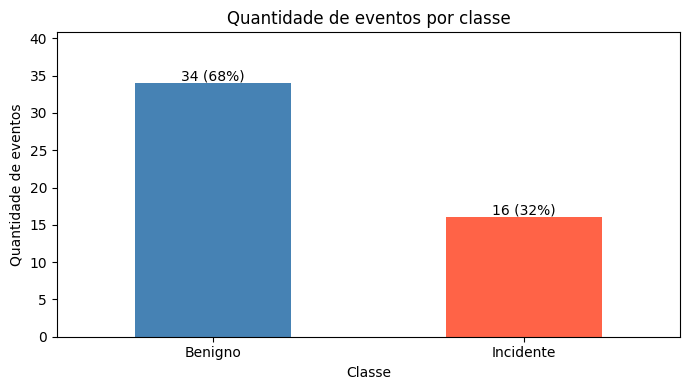

**Resposta:** Há 34 eventos benignos (68%) e 16 incidentes (32%). Os eventos benignos são a maioria nesta amostra.

In [4]:
rotulos = {0: 'Benigno', 1: 'Incidente'}
contagens = dados['incidente'].value_counts().reindex([0, 1], fill_value=0)
proporcoes = pd.DataFrame({'Quantidade': contagens, 'Percentual (%)': contagens / len(dados) * 100})
proporcoes.index = proporcoes.index.map(rotulos)
display(proporcoes.round(2))
ax = proporcoes['Quantidade'].plot.bar(color=['steelblue', 'tomato'], rot=0)
ax.set(title='Quantidade de eventos por classe', xlabel='Classe', ylabel='Quantidade de eventos')
for barra, percentual in zip(ax.patches, proporcoes['Percentual (%)']):
    ax.annotate(f'{int(barra.get_height())} ({percentual:.0f}%)', (barra.get_x() + barra.get_width()/2, barra.get_height()), ha='center', va='bottom')
ax.set_ylim(0, contagens.max() * 1.2)
plt.tight_layout()
plt.show()
display(Markdown(f"**Resposta:** Há {contagens[0]} eventos benignos ({proporcoes.iloc[0, 1]:.0f}%) e {contagens[1]} incidentes ({proporcoes.iloc[1, 1]:.0f}%). Os eventos benignos são a maioria nesta amostra."))

## Questão 2 — Média e mediana das falhas de login

,Média,Mediana
incidente,,
Benigno,2.06,1.0
Incidente,12.31,14.0


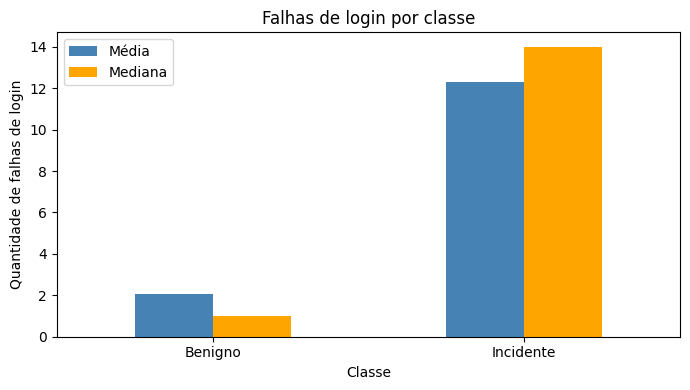

**Resposta:** Nos eventos benignos, a média é 2.06 e a mediana é 1.00. Nos incidentes, são 12.31 e 14.00. As duas medidas são maiores nos incidentes, indicando associação entre mais falhas de login e incidentes nesta amostra. Essa associação não significa que uma quantidade isolada de falhas determine a classe.

In [5]:
resumo_login = dados.groupby('incidente')['falhas_login'].agg(['mean', 'median'])
resumo_login.columns = ['Média', 'Mediana']
resumo_login.index = resumo_login.index.map(rotulos)
display(resumo_login.round(2))
ax = resumo_login.plot.bar(rot=0, color=['steelblue', 'orange'])
ax.set(title='Falhas de login por classe', xlabel='Classe', ylabel='Quantidade de falhas de login')
plt.tight_layout()
plt.show()
b = resumo_login.loc['Benigno']
i = resumo_login.loc['Incidente']
display(Markdown(f"**Resposta:** Nos eventos benignos, a média é {b['Média']:.2f} e a mediana é {b['Mediana']:.2f}. Nos incidentes, são {i['Média']:.2f} e {i['Mediana']:.2f}. As duas medidas são maiores nos incidentes, indicando associação entre mais falhas de login e incidentes nesta amostra. Essa associação não significa que uma quantidade isolada de falhas determine a classe."))

## Questão 3 — Tráfego elevado significa necessariamente incidente?
Comparamos as distribuições e os valores individuais. Os extremos observados servem como referência para a comparação, sem criar um limite de classificação.

,Mínimo (MB),Mediana (MB),Máximo (MB)
incidente,,,
Benigno,6.2,124.35,566.0
Incidente,113.8,421.30,894.8


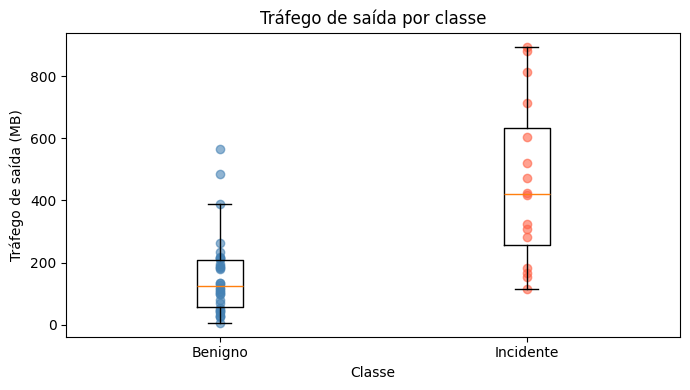

,falhas_login,ips_origem,trafego_saida_mb,hora_evento,incidente
1,1,1,113.8,21,1
18,1,3,566.0,4,0


**Resposta:** Não. Há evento benigno com 566.0 MB e incidente com apenas 113.8 MB. O maior tráfego benigno supera o menor tráfego de incidente, mostrando sobreposição entre as classes. Portanto, um volume maior de tráfego, isoladamente, não determina que houve incidente.

In [6]:
trafego = dados.groupby('incidente')['trafego_saida_mb'].agg(['min', 'median', 'max'])
trafego.columns = ['Mínimo (MB)', 'Mediana (MB)', 'Máximo (MB)']
trafego.index = trafego.index.map(rotulos)
display(trafego)
fig, ax = plt.subplots()
grupos = [dados.loc[dados['incidente'] == c, 'trafego_saida_mb'] for c in [0, 1]]
ax.boxplot(grupos, showfliers=False)
for posicao, valores in enumerate(grupos, start=1):
    ax.scatter([posicao] * len(valores), valores, alpha=0.6, color=['steelblue', 'tomato'][posicao-1])
ax.set_xticks([1, 2], ['Benigno', 'Incidente'])
ax.set(title='Tráfego de saída por classe', xlabel='Classe', ylabel='Tráfego de saída (MB)')
plt.tight_layout()
plt.show()
max_benigno = grupos[0].max()
min_incidente = grupos[1].min()
exemplos = dados.loc[((dados['incidente'] == 0) & (dados['trafego_saida_mb'] == max_benigno)) | ((dados['incidente'] == 1) & (dados['trafego_saida_mb'] == min_incidente))]
display(exemplos)
display(Markdown(f"**Resposta:** Não. Há evento benigno com {max_benigno:.1f} MB e incidente com apenas {min_incidente:.1f} MB. O maior tráfego benigno supera o menor tráfego de incidente, mostrando sobreposição entre as classes. Portanto, um volume maior de tráfego, isoladamente, não determina que houve incidente."))

## Questão 4 — Treinamento do classificador
Usamos Regressão Logística com as quatro variáveis de entrada. A divisão é estratificada, com 80% para treinamento e 20% para teste e `random_state=42`. A padronização integra o pipeline e é ajustada apenas no treinamento. O conjunto de teste será usado somente na avaliação final.

In [7]:
entradas = ['falhas_login', 'ips_origem', 'trafego_saida_mb', 'hora_evento']
X = dados[entradas]
y = dados['incidente']
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
modelo = Pipeline([
    ('padronizacao', StandardScaler()),
    ('classificador', LogisticRegression(random_state=42, max_iter=1000))
])
modelo.fit(X_treino, y_treino)
print(f'Treinamento: {len(X_treino)} eventos; teste: {len(X_teste)} eventos.')
display(pd.DataFrame({'Treinamento': y_treino.value_counts(), 'Teste': y_teste.value_counts()}).rename(index=rotulos))

,Treinamento,Teste
incidente,,
Benigno,27,7
Incidente,13,3


Treinamento: 40 eventos; teste: 10 eventos.


## Avaliação do classificador
A classe positiva é 1 (incidente). A matriz apresenta as classes reais nas linhas e as previstas nas colunas.

,Valor (%)
Acurácia,90.00
Precisão,100.00
Recall,66.67
F1-score,80.00


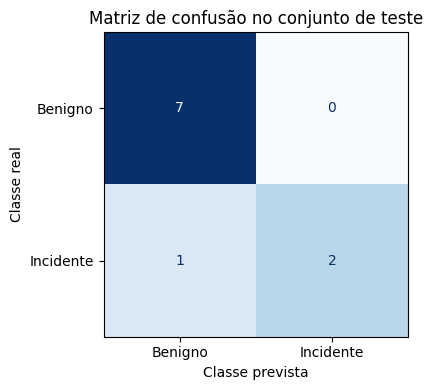

**Interpretação:** O modelo acertou 7 eventos benignos e 2 incidentes. Houve 0 falso(s) positivo(s), isto é, eventos benignos classificados como incidentes, que podem gerar investigação desnecessária. Houve 1 falso(s) negativo(s), incidentes classificados como benignos, que podem deixar ameaças sem tratamento. A avaliação usa somente 10 eventos de teste de um total de 50 registros; as métricas não garantem o mesmo desempenho em outros eventos.

In [8]:
previsoes = modelo.predict(X_teste)
acuracia = accuracy_score(y_teste, previsoes)
precisao = precision_score(y_teste, previsoes, pos_label=1, zero_division=0)
recall = recall_score(y_teste, previsoes, pos_label=1, zero_division=0)
f1 = f1_score(y_teste, previsoes, pos_label=1, zero_division=0)
metricas = pd.DataFrame({'Valor (%)': [acuracia*100, precisao*100, recall*100, f1*100]}, index=['Acurácia', 'Precisão', 'Recall', 'F1-score'])
display(metricas.round(2))
matriz = confusion_matrix(y_teste, previsoes, labels=[0, 1])
vn, fp, fn, vp = matriz.ravel()
fig, ax = plt.subplots()
ConfusionMatrixDisplay(matriz, display_labels=['Benigno', 'Incidente']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set(title='Matriz de confusão no conjunto de teste', xlabel='Classe prevista', ylabel='Classe real')
plt.tight_layout()
plt.show()
display(Markdown(f"**Interpretação:** O modelo acertou {vn} eventos benignos e {vp} incidentes. Houve {fp} falso(s) positivo(s), isto é, eventos benignos classificados como incidentes, que podem gerar investigação desnecessária. Houve {fn} falso(s) negativo(s), incidentes classificados como benignos, que podem deixar ameaças sem tratamento. A avaliação usa somente {len(y_teste)} eventos de teste de um total de {len(dados)} registros; as métricas não garantem o mesmo desempenho em outros eventos."))

## Parágrafo obrigatório — Opinião em até 1000 caracteres

In [9]:
opiniao = (
    f'Como estudante de Cibersegurança, avalio que o classificador obteve acurácia de {acuracia:.1%}, '
    f'precisão de {precisao:.1%}, recall de {recall:.1%} e F1-score de {f1:.1%} no teste. '
    f'Na matriz de confusão, identificou corretamente {vp} incidentes e {vn} eventos benignos, '
    f'com {fp} falso(s) positivo(s) e {fn} falso(s) negativo(s). '
    f'Os falsos positivos geram alertas indevidos; os falsos negativos representam incidentes que o modelo deixou passar. '
    f'Considero o recall relevante para avaliar essa perda de incidentes e a precisão para avaliar os alertas emitidos. '
    f'O F1-score resume o equilíbrio entre essas duas métricas. '
    f'Como o teste tem apenas {len(y_teste)} eventos e o dataset contém {len(dados)} registros, '
    f'não considero a acurácia suficiente para afirmar que o modelo é confiável.'
)
assert len(opiniao) <= 1000, 'O parágrafo ultrapassou 1000 caracteres.'
display(Markdown(opiniao))
print(f'Caracteres, incluindo espaços: {len(opiniao)}')

Como estudante de Cibersegurança, avalio que o classificador obteve acurácia de 90.0%, precisão de 100.0%, recall de 66.7% e F1-score de 80.0% no teste. Na matriz de confusão, identificou corretamente 2 incidentes e 7 eventos benignos, com 0 falso(s) positivo(s) e 1 falso(s) negativo(s). Os falsos positivos geram alertas indevidos; os falsos negativos representam incidentes que o modelo deixou passar. Considero o recall relevante para avaliar essa perda de incidentes e a precisão para avaliar os alertas emitidos. O F1-score resume o equilíbrio entre essas duas métricas. Como o teste tem apenas 10 eventos e o dataset contém 50 registros, não considero a acurácia suficiente para afirmar que o modelo é confiável.

Caracteres, incluindo espaços: 719


## Conclusão
Os dados permitem comparar a proporção de incidentes, as falhas de login e o tráfego de saída entre as classes. As falhas de login são maiores nos incidentes nesta amostra, enquanto o tráfego apresenta sobreposição entre as classes. O classificador foi avaliado em dados separados do treinamento; suas métricas e erros devem ser interpretados considerando o pequeno tamanho do dataset.